# Atividade 1 - Primeiro contato com PyTorch — Cat vs. Not Cat

## Objetivo
Construir uma rede neural simples para classificar imagens como gato ou não-gato.

O código não está pronto. Em cada etapa, você deverá desenvolver sua solução.

**Fluxo:** dados → rede neural → treinamento → resultado → uma alteração → comparação

### Dataset

O dataset desta atividade é o arquivo **`cat_not_cat.csv`**. Esse arquivo não possui cabeçalho. Cada linha representa uma imagem. As primeiras colunas contêm os valores dos pixels, e a última coluna contém o label da imagem.

O arquivo deve ficar na mesma pasta do notebook; caso contrário, ajuste o caminho no código.

> O objetivo desta atividade também é desenvolver sua autonomia na busca por conhecimento. Se você não souber como fazer algo, seja utilizar o GitHub, implementar uma etapa ou entender um conceito, pesquise e busque compreender antes de seguir. Faz parte da atividade aprender a encontrar as respostas.

> Você não precisa entender ainda toda a matemática do treinamento. Neste momento, o objetivo é aprender a usar o PyTorch e reconhecer as principais etapas.

In [1]:
!pip install numpy pandas matplotlib scikit-learn torch torchvision

## 0. Prepare sua branch no repositório

Antes de iniciar a atividade, acesse o repositório do projeto e crie uma branch própria para desenvolver e salvar seu exercício.

Repositório: https://github.com/LCCMat-UnB/segmentacao-laminas

Cada aluno deverá trabalhar em uma branch separada, sem alterar diretamente a branch main.

Use um nome que identifique claramente sua branch, por exemplo:

`atividade-1-seunome`

Não adicione o arquivo `cat_not_cat.csv` à sua branch. Faça o commit apenas do notebook e dos arquivos produzidos pela atividade.

Durante o desenvolvimento da atividade:

1. salve o notebook da atividade na sua branch;
2. faça commits ao longo do trabalho;
3. mantenha suas alterações apenas na sua branch;
4. ao finalizar a atividade, faça o último commit com a versão completa do notebook.

## 1. Conheça o dataset
Nesta etapa, você vai entender os dados antes de treinar o modelo.

Use as células de código abaixo para:
1. carregar o arquivo `cat_not_cat.csv`;
2. observar o formato de `X` e `y`;
3. visualizar algumas imagens.

### Responda
1. Quantos exemplos existem no dataset?
2. O que representa `X`?
3. O que representa `y`?
4. Quais são as duas classes?
5. Como uma imagem está representada nos dados?

In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Lendo o arquivo CSV
df = pd.read_csv("/cat_not_cat.csv", header=None)

# Removendo linhas e colunas totalmente vazias
df = df.dropna(how="all")
df = df.dropna(axis=1, how="all")

# Verificando se os dados estão completos
print("Formato do arquivo:", df.shape)
print("Valores ausentes:", df.isna().sum().sum())

# Separando os pixels e os rótulos
X = df.iloc[:, :-1].values
y = df.iloc[:, -1].astype(int).values

# Mostrando informações do dataset
print("Formato de X:", X.shape)
print("Formato de y:", y.shape)
print("Classes:", np.unique(y))
print("Quantidade por classe:", dict(zip(*np.unique(y, return_counts=True))))

Formato do arquivo: (258, 12289)
Valores ausentes: 0
Formato de X: (258, 12288)
Formato de y: (258,)
Classes: [0 1]
Quantidade por classe: {np.int64(0): np.int64(154), np.int64(1): np.int64(104)}


Label da imagem 0: 0
Primeiros 10 pixels da imagem 0: [17. 31. 56. 22. 33. 59. 25. 35. 62. 25.]


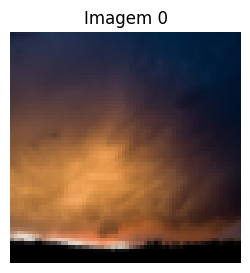

In [5]:
# Exemplo: olhando a primeira linha do CSV
print("Label da imagem 0:", y[0])
print("Primeiros 10 pixels da imagem 0:", X[0, :10])

# Para visualizar, reorganizamos os 12288 pixels para 64x64x3 (64x64x3=12288)
img0 = X[0].reshape(64, 64, 3).astype("uint8")
plt.figure(figsize=(3, 3))
plt.imshow(img0)
plt.title("Imagem 0")
plt.axis("off")
plt.show()

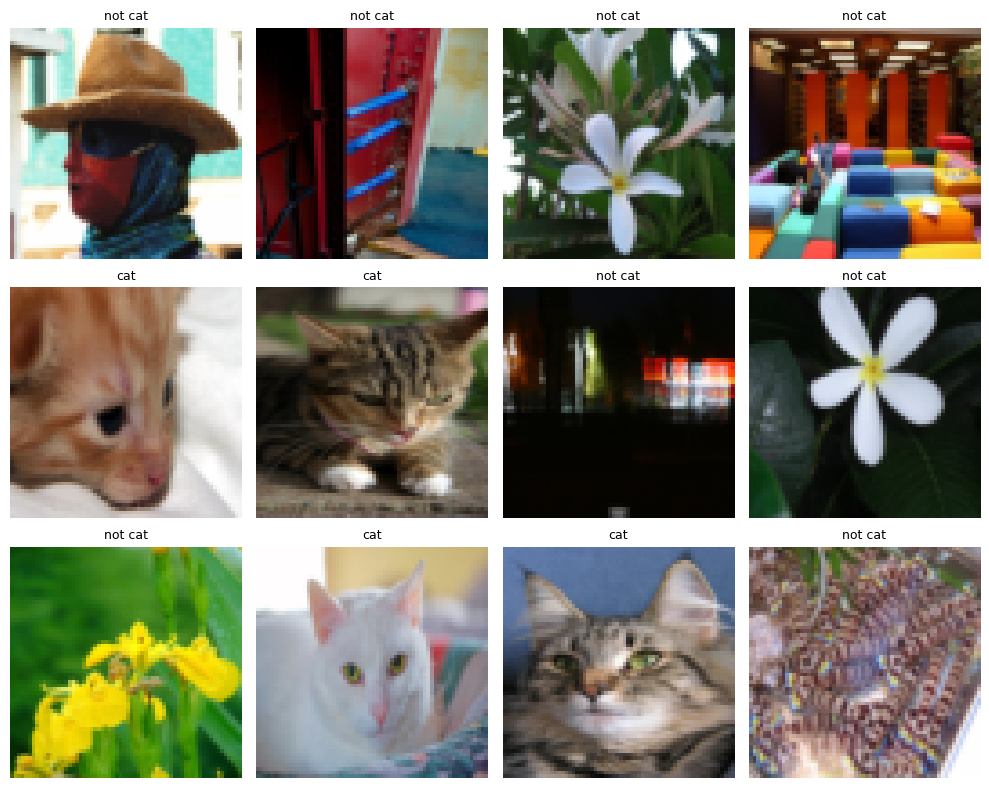

In [6]:
# Mostra 12 imagens aleatórias do dataset
n_images = 12
np.random.seed(42)
indices = np.random.choice(len(X), n_images, replace=False)

fig, axes = plt.subplots(3, 4, figsize=(10, 8))
for ax, i in zip(axes.flatten(), indices):
    img = X[i].reshape(64, 64, 3).astype("uint8")
    label = "cat" if y[i] == 1 else "not cat"

    ax.imshow(img)
    ax.set_title(label, fontsize=9)
    ax.axis("off")

plt.tight_layout()
plt.show()

### Respostas — 1. Dataset
1. O dataset tem 258 imagens: 104 de gatos e 154 de não gatos.
2. `X` guarda os pixels das imagens que vamos passar para a rede.
3. `y` informa a classe correta de cada imagem.
4. As classes são 0 (não gato) e 1 (gato).
5. Cada imagem aparece como uma sequência de 12.288 valores. Esses valores formam uma imagem de 64 × 64 pixels, com as três cores RGB.


## 2. Separe os dados em treino e teste
Agora que você já tem o dataset carregado em `X` e `y`, o próximo passo é separar em:
- **treino:** dados usados para o modelo aprender;
- **teste:** dados usados para verificar se o modelo generaliza.

Utilize `random_state=42` para tornar a divisão reproduzível e preserve a proporção das classes nos dois conjuntos.

### Responda
1. Qual proporção você escolheu e por que?
2. Qual é o sentido de separar os dados em treino e teste?
3. Por que não devemos avaliar o modelo somente nos dados usados no treinamento?

> Nesta atividade introdutória, utilizaremos o conjunto de teste para uma comparação simples. Em projetos reais, normalmente mantemos um conjunto de validação para escolher configurações e reservamos o teste para a avaliação final.

In [7]:
from sklearn.model_selection import train_test_split

# Separei 80% para treinar e 20% para testar.
# stratify mantém aproximadamente a proporção de gatos e não gatos.
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)
print("Imagens de treino:", len(X_train))
print("Imagens de teste:", len(X_test))


Imagens de treino: 206
Imagens de teste: 52


### Respostas — 2. Treino e teste
1. Separei 80% para treino (206 imagens) e 20% para teste (52 imagens). Assim, a rede tem mais dados para aprender, mas ainda sobram imagens para testar.
2. No treino, a rede ajusta seus pesos. No teste, vemos se ela consegue acertar imagens que não foram usadas no treinamento.
3. Porque ela poderia acertar as imagens que já viu, mas errar quando recebesse imagens novas.


## 3. Prepare os dados

Antes de treinar o modelo, investigue como os valores dos pixels estão representados no dataset.

Verifique o menor e o maior valor encontrado e pesquise se é necessário realizar alguma transformação nesses valores antes de fornecê-los à rede neural.

Depois, transforme os dados para o formato utilizado pelo PyTorch.

Verifique também qual deve ser o tipo (`dtype`) dos tensores de entrada e dos labels para utilizar a `BCEWithLogitsLoss`.

### Responda
1. Qual é o menor e o maior valor dos pixels?
2. Foi necessário normalizar os dados? Por quê?
3. Qual transformação você realizou?
4. Por que escolheu essa transformação?
5. O que é um tensor?

In [8]:
import torch

print("Pixel mínimo:", X.min())
print("Pixel máximo:", X.max())

# Os pixels vão de 0 a 255; dividindo por 255 ficam entre 0 e 1.
X_train = X_train.astype(np.float32) / 255.0
X_test = X_test.astype(np.float32) / 255.0

# Entradas e labels como float32. O reshape faz os labels terem formato (N, 1).
X_train_tensor = torch.tensor(X_train, dtype=torch.float32)
X_test_tensor = torch.tensor(X_test, dtype=torch.float32)
y_train_tensor = torch.tensor(y_train, dtype=torch.float32).reshape(-1, 1)
y_test_tensor = torch.tensor(y_test, dtype=torch.float32).reshape(-1, 1)

print("Entrada:", X_train_tensor.shape, X_train_tensor.dtype)
print("Labels:", y_train_tensor.shape, y_train_tensor.dtype)


Pixel mínimo: 0.0
Pixel máximo: 255.0
Entrada: torch.Size([206, 12288]) torch.float32
Labels: torch.Size([206, 1]) torch.float32


### Respostas — 3. Preparação
1. Os pixels vão de 0 a 255.
2. Sim. É melhor normalizar os valores antes de treinar a rede.
3. Dividi os pixels por 255, deixando os valores entre 0 e 1. Depois, transformei os dados em tensores `float32` e deixei os rótulos no formato `(N, 1)`.
4. Fiz isso para trabalhar com valores menores, o que facilita o treinamento.
5. Um tensor é parecido com um array do NumPy. É o tipo de dado que o PyTorch usa para fazer os cálculos da rede.


## 4. Organize os dados para o treinamento
Use o **DataLoader** do PyTorch para organizar os dados de treino.

Para o baseline, utilize **batch size = 32**.

### Responda
1. O que é um DataLoader?
2. O que é um batch?
3. O que significa batch size = 32?
4. Por que embaralhamos os dados de treino?

In [9]:
from torch.utils.data import TensorDataset, DataLoader

# Junta cada imagem ao seu respectivo label.
dataset_treino = TensorDataset(X_train_tensor, y_train_tensor)

# O DataLoader entrega lotes de 32 imagens e embaralha os dados a cada época.
loader_treino = DataLoader(dataset_treino, batch_size=32, shuffle=True)
print("Número de batches:", len(loader_treino))


Número de batches: 7


### Respostas — 4. DataLoader
1. O `DataLoader` organiza os dados e entrega as imagens para a rede durante o treino.
2. Um batch é um grupo de imagens usado de uma vez.
3. `batch_size=32` quer dizer que a rede treina com até 32 imagens por vez.
4. Embaralhamos os dados para a rede não receber as imagens sempre na mesma ordem.


## 5. Crie a rede neural

Crie uma rede neural simples:

**entrada → camada com 16 neurônios → ReLU → uma saída (logit)**

Como este é um problema binário (gato ou não-gato), use um neurônio de saída. Não inclua a função `sigmoid` na arquitetura do modelo. A `BCEWithLogitsLoss` já realiza essa operação internamente durante o cálculo da loss.

### Responda
1. Quantos valores entram na rede para cada exemplo?
2. Quantos neurônios existem na camada intermediária?
3. Qual função de ativação você utilizou?
4. Quantas saídas sua rede possui?
5. Por que você escolheu essa função de ativação?

In [10]:
import torch.nn as nn

# Fixei uma semente para facilitar a reprodução dos resultados.
torch.manual_seed(42)

# Cada imagem entra como um vetor com 12.288 valores.
# A camada oculta tem 16 neurônios e a saída tem um único logit.
modelo = nn.Sequential(
    nn.Linear(12288, 16),
    nn.ReLU(),
    nn.Linear(16, 1)
)
print(modelo)


Sequential(
  (0): Linear(in_features=12288, out_features=16, bias=True)
  (1): ReLU()
  (2): Linear(in_features=16, out_features=1, bias=True)
)


### Respostas — 5. Rede neural
1. Entram 12.288 valores, que são os pixels de uma imagem.
2. A camada do meio tem 16 neurônios.
3. Usei a função ReLU.
4. A rede tem uma saída, pois precisa decidir entre duas classes.
5. A ReLU ajuda a rede a aprender padrões que não seriam representados só com operações lineares.


## 6. Configure o treinamento

- **Loss:** `BCEWithLogitsLoss`;
- **Optimizer:** Adam;
- **Learning rate:** 0.001;
- **Epochs:** 10.

**Baseline** é o modelo inicial que será usado como referência.

Como este problema é binário, usamos 1 saída (logit) e `BCEWithLogitsLoss`, que já combina sigmoid + binary cross-entropy com melhor estabilidade numérica.

Dica prática: garanta que `y` esteja em `float32` e com o mesmo formato da saída do modelo (por exemplo, `[batch, 1]`).

### Responda

1. O que é a loss?
2. Por que `BCEWithLogitsLoss` é adequada neste caso?
3. O que o optimizer faz?
4. O que é o learning rate?
5. O que é uma epoch?

In [12]:
# A loss mede a diferença entre previsões e labels reais.
criterio = nn.BCEWithLogitsLoss()

# O Adam ajusta os pesos usando a taxa de aprendizado definida.
otimizador = torch.optim.Adam(modelo.parameters(), lr=0.001)

numero_epocas = 10


### Respostas — 6. Configuração
1. A loss indica o quanto a rede está errando nas previsões.
2. Escolhi `BCEWithLogitsLoss` porque estamos classificando imagens em duas classes e a rede tem uma saída.
3. O otimizador muda os pesos da rede para tentar diminuir o erro.
4. O learning rate define o tamanho dessas mudanças. Usei 0,001.
5. Uma época acontece quando a rede passa por todos os dados de treinamento uma vez.


## 7. Treine o baseline
Implemente o treinamento.

O modelo deverá:
1. receber os dados;
2. fazer uma previsão;
3. calcular o erro;
4. aprender a partir desse erro.

Registre a **loss de cada epoch**.

### Responda
1. A loss diminuiu durante o treinamento?
2. O que isso indica?
3. Qual foi a loss final?

In [13]:
historico_loss = []

for epoca in range(numero_epocas):
    modelo.train()  # Ativa o modo de treinamento.
    perda_total = 0.0

    for imagens, rotulos in loader_treino:
        otimizador.zero_grad()  # Limpa os gradientes anteriores.
        logits = modelo(imagens)  # Faz as previsões.
        perda = criterio(logits, rotulos)  # Calcula a loss.
        perda.backward()  # Calcula os gradientes.
        otimizador.step()  # Atualiza os pesos da rede.
        perda_total += perda.item() * imagens.size(0)

    # Calcula a loss média por imagem nesta época.
    loss_media = perda_total / len(dataset_treino)
    historico_loss.append(loss_media)
    print(f"Epoch {epoca + 1}: Loss = {loss_media:.4f}")


Epoch 1: Loss = 1.1003
Epoch 2: Loss = 0.6759
Epoch 3: Loss = 0.6781
Epoch 4: Loss = 0.6780
Epoch 5: Loss = 0.6779
Epoch 6: Loss = 0.6778
Epoch 7: Loss = 0.6777
Epoch 8: Loss = 0.6777
Epoch 9: Loss = 0.6776
Epoch 10: Loss = 0.6775


### Respostas — 7. Treinamento do baseline
1. Sim, a loss começou em 1.1003 e terminou em 0.6775.
2. Isso indica que, nos dados de treino, o modelo conseguiu reduzir seus erros. Porém, apenas a loss de treino não comprova que ele generaliza bem.
3. A loss final do baseline foi 0.6775.


## 8. Veja o resultado
Crie um gráfico da **loss ao longo das epochs** e calcule a **accuracy** nos dados de teste.

Como a saída do modelo é um logit, aplique `torch.sigmoid()` durante a avaliação para obter uma probabilidade. Considere valores maiores ou iguais a `0.5` como classe 1 e valores menores que `0.5` como classe 0.

### Registre
**Accuracy do baseline:**  
**Loss final do baseline:**  

### Responda
1. O que o gráfico da loss mostra?
2. Qual foi a accuracy?
3. O que significa, por exemplo, uma accuracy de 80%?

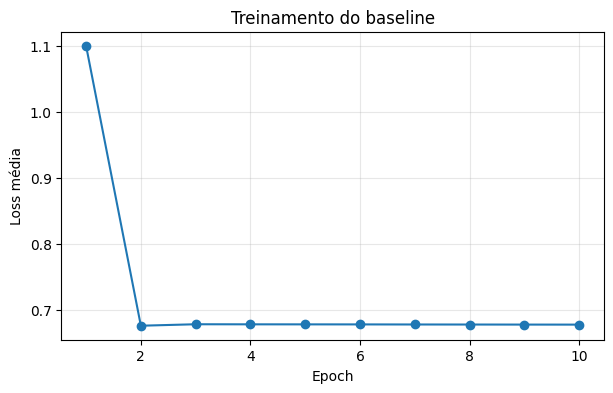

Accuracy do baseline: 59.62%
Loss final do baseline: 0.6775


In [14]:
# Gráfico do erro ao longo do treinamento.
plt.figure(figsize=(7, 4))
plt.plot(range(1, numero_epocas + 1), historico_loss, marker="o")
plt.xlabel("Epoch")
plt.ylabel("Loss média")
plt.title("Treinamento do baseline")
plt.grid(alpha=0.3)
plt.show()

# Avalia usando apenas imagens que não entraram no treinamento.
modelo.eval()
with torch.no_grad():
    logits_teste = modelo(X_test_tensor)
    probabilidades = torch.sigmoid(logits_teste)
    previsoes = (probabilidades >= 0.5).float()
    accuracy_baseline = (previsoes == y_test_tensor).float().mean().item() * 100

loss_final_baseline = historico_loss[-1]
print(f"Accuracy do baseline: {accuracy_baseline:.2f}%")
print(f"Loss final do baseline: {loss_final_baseline:.4f}")


### Respostas — 8. Resultado do baseline
Accuracy do baseline: 59,62%  
Loss final do baseline: 0,6775

1. O gráfico mostra como o erro do treinamento mudou ao longo das épocas. Nesse caso, a loss foi diminuindo.
2. A accuracy no teste foi de 59,62%.
3. Uma accuracy de 80% significa que, de cada 100 imagens, o modelo acertaria cerca de 80. É uma forma simples de medir os acertos.


## 9. Faça uma alteração

Escolha uma única característica do treinamento ou da rede para alterar. Pesquise uma possibilidade e explique por que decidiu testá-la.

Se precisar de ideias, você pode investigar alterações na quantidade de neurônios, learning rate, batch size ou número de epochs.

Crie e treine um novo modelo desde o início, mantendo a mesma divisão dos dados utilizada no baseline. Altere somente uma característica. Não continue o treinamento do modelo anterior.

Antes de testar, responda:

1. O que você vai alterar?
2. Por que escolheu isso?
3. O que você acha que vai acontecer?

### Respostas antes do experimento
1. Vou aumentar os neurônios da camada do meio de 16 para 32.
2. Escolhi isso para ver se uma rede um pouco maior consegue identificar melhor os padrões das imagens.
3. Acho que o erro de treino pode diminuir, mas não tenho certeza se a accuracy vai melhorar, porque o dataset é pequeno.


Epoch 1: Loss = 1.0000
Epoch 2: Loss = 0.6912
Epoch 3: Loss = 0.6879
Epoch 4: Loss = 0.6605
Epoch 5: Loss = 0.6610
Epoch 6: Loss = 0.6344
Epoch 7: Loss = 0.6311
Epoch 8: Loss = 0.6107
Epoch 9: Loss = 0.5969
Epoch 10: Loss = 0.5874
Accuracy com 32 neurônios: 71.15%
Loss final com 32 neurônios: 0.5874


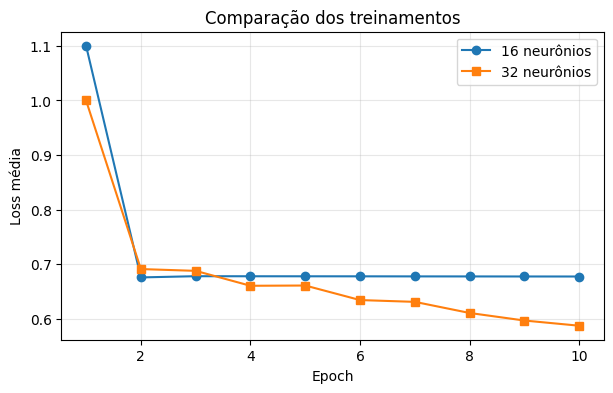

In [15]:
# Testei uma única mudança: 32 neurônios em vez de 16.
# Mantenho divisão dos dados, batch size, learning rate e 10 épocas.
torch.manual_seed(42)
modelo_32 = nn.Sequential(
    nn.Linear(12288, 32),
    nn.ReLU(),
    nn.Linear(32, 1)
)

criterio_32 = nn.BCEWithLogitsLoss()
otimizador_32 = torch.optim.Adam(modelo_32.parameters(), lr=0.001)
loader_32 = DataLoader(dataset_treino, batch_size=32, shuffle=True)
historico_loss_32 = []

for epoca in range(10):
    modelo_32.train()
    perda_total = 0.0
    for imagens, rotulos in loader_32:
        otimizador_32.zero_grad()
        logits = modelo_32(imagens)
        perda = criterio_32(logits, rotulos)
        perda.backward()
        otimizador_32.step()
        perda_total += perda.item() * imagens.size(0)

    loss_media = perda_total / len(dataset_treino)
    historico_loss_32.append(loss_media)
    print(f"Epoch {epoca + 1}: Loss = {loss_media:.4f}")

# Accuracy do modelo modificado.
modelo_32.eval()
with torch.no_grad():
    prob_32 = torch.sigmoid(modelo_32(X_test_tensor))
    previsoes_32 = (prob_32 >= 0.5).float()
    accuracy_32 = (previsoes_32 == y_test_tensor).float().mean().item() * 100

loss_final_32 = historico_loss_32[-1]
print(f"Accuracy com 32 neurônios: {accuracy_32:.2f}%")
print(f"Loss final com 32 neurônios: {loss_final_32:.4f}")

# Comparo a evolução da loss dos dois modelos.
plt.figure(figsize=(7, 4))
plt.plot(range(1, 11), historico_loss, marker="o", label="16 neurônios")
plt.plot(range(1, 11), historico_loss_32, marker="s", label="32 neurônios")
plt.xlabel("Epoch")
plt.ylabel("Loss média")
plt.title("Comparação dos treinamentos")
plt.legend()
plt.grid(alpha=0.3)
plt.show()


## 10. Compare
Compare seu experimento com o baseline.

| | Baseline | Meu experimento |
|---|---|---|
| O que mudou? | — | |
| Accuracy | | |
| Loss final | | |

### Responda
1. O que você mudou?
2. A accuracy aumentou ou diminuiu?
3. A loss mudou?
4. O que você observou?

### Comparação final

| | Modelo inicial | Modelo alterado |
|---|---|---|
| Neurônios na camada do meio | 16 | 32 |
| Accuracy | 59,62% | 71,15% |
| Loss final (treino) | 0,6775 | 0,5874 |

### Respostas — 10. Comparação
1. Aumentei de 16 para 32 neurônios na camada intermediária.
2. A accuracy subiu de 59,62% para 71,15%.
3. A loss diminuiu de 0,6775 para 0,5874.
4. Nesse teste, a rede com 32 neurônios teve um resultado melhor. Mesmo assim, não dá para afirmar que mais neurônios sempre melhoram o modelo, ainda mais porque usamos poucas imagens.
